In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")


In [37]:

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

sns.set_style("whitegrid")

In [38]:
df = pd.read_csv(
    "/Users/mac/Downloads/uber_fare_prediction_api/data/uber_trips_dataset_50k.csv"
)

print(df.shape)
display(df.head())

(50000, 14)


,trip_id,driver_id,rider_id,city,pickup_lat,pickup_lng,drop_lat,drop_lng,distance_km,fare_amount,status,payment_method,pickup_time,drop_time
0,1,8270,10683,San Francisco,37.170931,-77.586479,37.173652,-77.619934,2.97,10.71,Completed,Wallet,2023-01-01 00:00:00,2023-01-01 00:08:54.600000000
1,2,1860,44743,Boston,38.898127,-108.582977,38.937464,-108.558727,8.43,22.41,Completed,UPI,2023-01-01 00:01:00,2023-01-01 00:26:17.400000000
2,3,6390,75839,San Francisco,38.814571,-89.942603,38.821702,-89.896435,5.46,12.91,Completed,Cash,2023-01-01 00:02:00,2023-01-01 00:18:22.800000000
3,4,6191,22189,New York,37.295906,-75.328844,37.301375,-75.317488,6.61,15.70,Completed,Wallet,2023-01-01 00:03:00,2023-01-01 00:22:49.800000000
4,5,6734,61104,Seattle,38.972395,-121.482913,38.992088,-121.467904,10.50,19.15,Completed,Wallet,2023-01-01 00:04:00,2023-01-01 00:35:30.000000000


In [39]:

# ============================================================
# 3. DATA UNDERSTANDING
# ============================================================

print("\n--- DATA INFORMATION ---")
df.info()

print("\n--- STATISTICAL SUMMARY ---")
print(df.describe())

print("\n--- COLUMN NAMES ---")
print(df.columns.tolist())

print("\n--- DATA TYPES ---")
print(df.dtypes)




--- DATA INFORMATION ---
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   trip_id         50000 non-null  int64  
 1   driver_id       50000 non-null  int64  
 2   rider_id        50000 non-null  int64  
 3   city            50000 non-null  str    
 4   pickup_lat      50000 non-null  float64
 5   pickup_lng      50000 non-null  float64
 6   drop_lat        50000 non-null  float64
 7   drop_lng        50000 non-null  float64
 8   distance_km     50000 non-null  float64
 9   fare_amount     50000 non-null  float64
 10  status          50000 non-null  str    
 11  payment_method  50000 non-null  str    
 12  pickup_time     50000 non-null  str    
 13  drop_time       50000 non-null  str    
dtypes: float64(6), int64(3), str(5)
memory usage: 8.7 MB

--- STATISTICAL SUMMARY ---
            trip_id     driver_id      rider_id    pickup_lat    pick

In [40]:

# ============================================================
# 4. DATA QUALITY ANALYSIS
# ============================================================

print("\n--- MISSING VALUES ---")
print(df.isnull().sum())

print("\n--- MISSING VALUE PERCENTAGE ---")
print((df.isnull().sum() / len(df)) * 100)

print("\n--- DUPLICATES ---")
print(df.duplicated().sum())

print("\n--- UNIQUE VALUES ---")
print(df.nunique())




--- MISSING VALUES ---
trip_id           0
driver_id         0
rider_id          0
city              0
pickup_lat        0
pickup_lng        0
drop_lat          0
drop_lng          0
distance_km       0
fare_amount       0
status            0
payment_method    0
pickup_time       0
drop_time         0
dtype: int64

--- MISSING VALUE PERCENTAGE ---
trip_id           0.0
driver_id         0.0
rider_id          0.0
city              0.0
pickup_lat        0.0
pickup_lng        0.0
drop_lat          0.0
drop_lng          0.0
distance_km       0.0
fare_amount       0.0
status            0.0
payment_method    0.0
pickup_time       0.0
drop_time         0.0
dtype: float64

--- DUPLICATES ---
0

--- UNIQUE VALUES ---
trip_id           50000
driver_id          8963
rider_id          38352
city                  6
pickup_lat        50000
pickup_lng        50000
drop_lat          50000
drop_lng          50000
distance_km        1623
fare_amount        3402
status                3
payment_method   

In [41]:

# ============================================================
# 5. DATA CLEANING
# ============================================================

df = df.drop_duplicates().copy()

df["distance_km"] = pd.to_numeric(
    df["distance_km"], errors="coerce"
)

df["fare_amount"] = pd.to_numeric(
    df["fare_amount"], errors="coerce"
)

df["pickup_time"] = pd.to_datetime(
    df["pickup_time"], errors="coerce"
)

df = df[
    (df["status"] == "Completed") &
    (df["distance_km"] > 0) &
    (df["fare_amount"] > 0)
].copy()

df = df.dropna(
    subset=[
        "distance_km",
        "fare_amount",
        "pickup_time",
        "city",
        "payment_method"
    ]
)

print("\nCLEANED DATASET SHAPE:", df.shape)




CLEANED DATASET SHAPE: (42538, 14)


In [42]:

# ============================================================
# 6. STATISTICAL ANALYSIS
# ============================================================

print("\n--- FARE STATISTICS ---")

print("Mean:", df["fare_amount"].mean())
print("Median:", df["fare_amount"].median())
print("Mode:", df["fare_amount"].mode().iloc[0])
print("Standard Deviation:", df["fare_amount"].std())
print("Minimum:", df["fare_amount"].min())
print("Maximum:", df["fare_amount"].max())

print("\n--- DISTANCE STATISTICS ---")
print(df["distance_km"].describe())



--- FARE STATISTICS ---
Mean: 15.978157177112228
Median: 15.43
Mode: 12.93
Standard Deviation: 6.27887356490203
Minimum: 1.08
Maximum: 48.2

--- DISTANCE STATISTICS ---
count    42538.000000
mean         7.009103
std          2.948904
min          0.010000
25%          4.970000
50%          6.970000
75%          9.010000
max         18.600000
Name: distance_km, dtype: float64


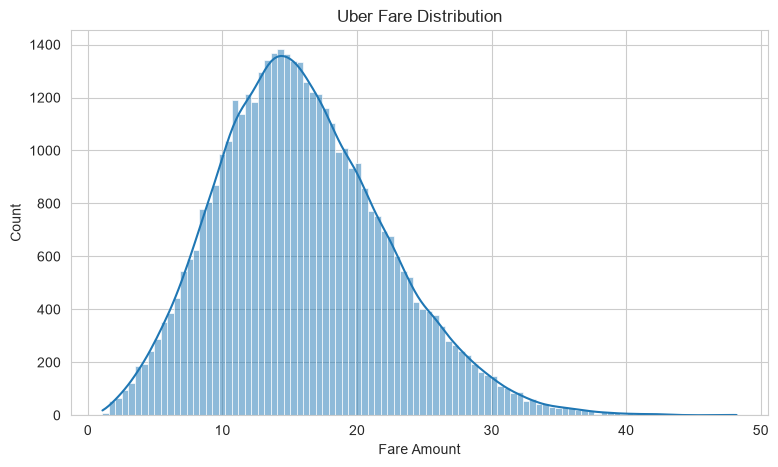

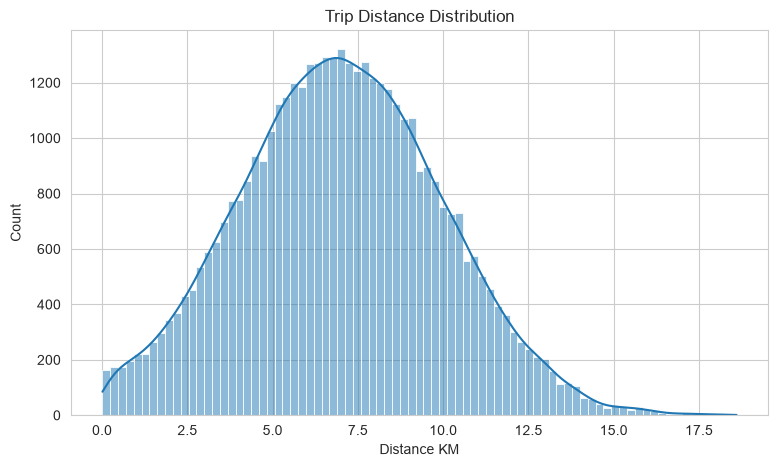

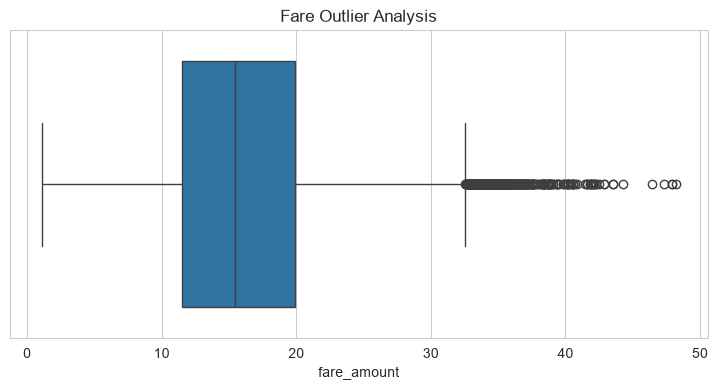

In [43]:


# ============================================================
# 7. UNIVARIATE ANALYSIS
# ============================================================

plt.figure(figsize=(9, 5))
sns.histplot(df["fare_amount"], kde=True)
plt.title("Uber Fare Distribution")
plt.xlabel("Fare Amount")
plt.show()

plt.figure(figsize=(9, 5))
sns.histplot(df["distance_km"], kde=True)
plt.title("Trip Distance Distribution")
plt.xlabel("Distance KM")
plt.show()

plt.figure(figsize=(9, 4))
sns.boxplot(x=df["fare_amount"])
plt.title("Fare Outlier Analysis")
plt.show()



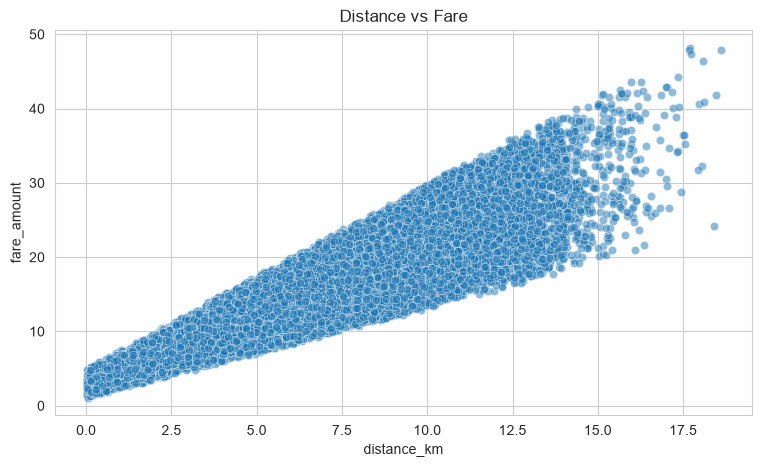

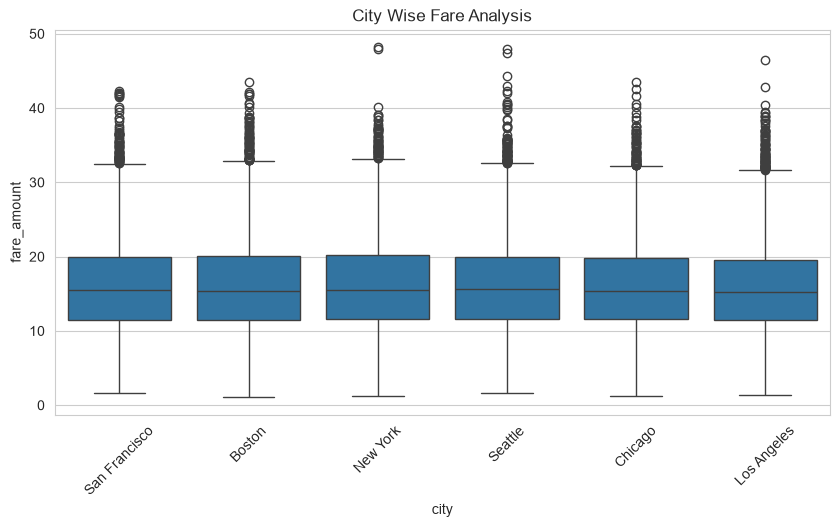

In [44]:

# ============================================================
# 8. BIVARIATE ANALYSIS
# ============================================================

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df,
    x="distance_km",
    y="fare_amount",
    alpha=0.5
)
plt.title("Distance vs Fare")
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x="city",
    y="fare_amount"
)
plt.title("City Wise Fare Analysis")
plt.xticks(rotation=45)
plt.show()



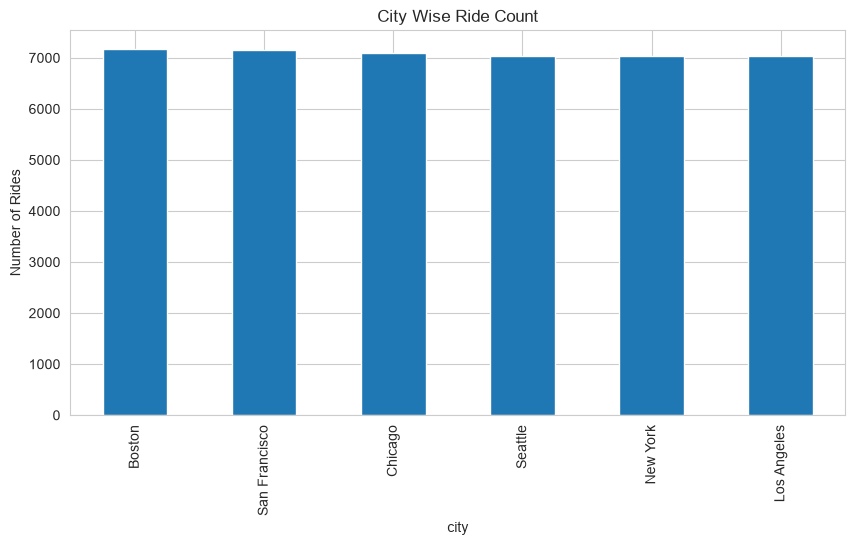

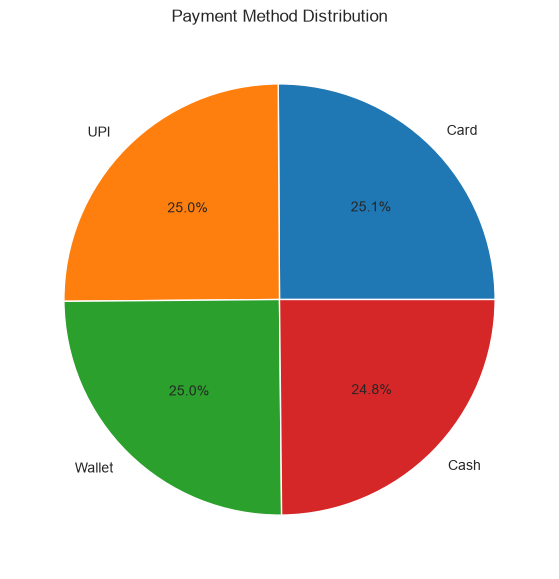

In [45]:

# ============================================================
# 9. CATEGORICAL ANALYSIS
# ============================================================

plt.figure(figsize=(10, 5))
df["city"].value_counts().plot(kind="bar")
plt.title("City Wise Ride Count")
plt.ylabel("Number of Rides")
plt.show()

plt.figure(figsize=(7, 7))
df["payment_method"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)
plt.title("Payment Method Distribution")
plt.ylabel("")
plt.show()



In [46]:

# ============================================================
# 10. FEATURE ENGINEERING
# ============================================================

df["hour"] = df["pickup_time"].dt.hour

df["day_of_week"] = df["pickup_time"].dt.dayofweek

df["day_name"] = df["pickup_time"].dt.day_name()

df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

print("\nFEATURE ENGINEERING COMPLETED")
print(df[[
    "pickup_time",
    "hour",
    "day_of_week",
    "day_name",
    "is_weekend"
]].head())




FEATURE ENGINEERING COMPLETED
          pickup_time  hour  day_of_week day_name  is_weekend
0 2023-01-01 00:00:00     0            6   Sunday           1
1 2023-01-01 00:01:00     0            6   Sunday           1
2 2023-01-01 00:02:00     0            6   Sunday           1
3 2023-01-01 00:03:00     0            6   Sunday           1
4 2023-01-01 00:04:00     0            6   Sunday           1


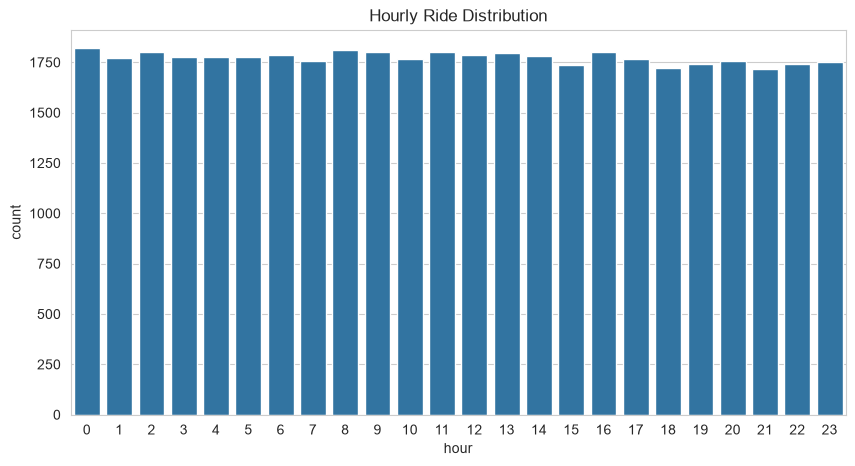

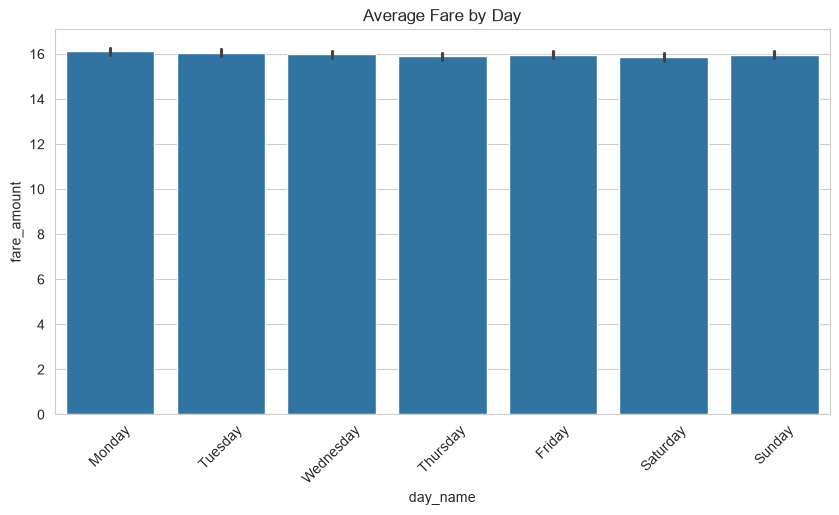

In [47]:

# ============================================================
# 11. TIME BASED ANALYSIS
# ============================================================

plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x="hour",
    order=range(24)
)
plt.title("Hourly Ride Distribution")
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(
    data=df,
    x="day_name",
    y="fare_amount",
    order=[
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ]
)
plt.title("Average Fare by Day")
plt.xticks(rotation=45)
plt.show()



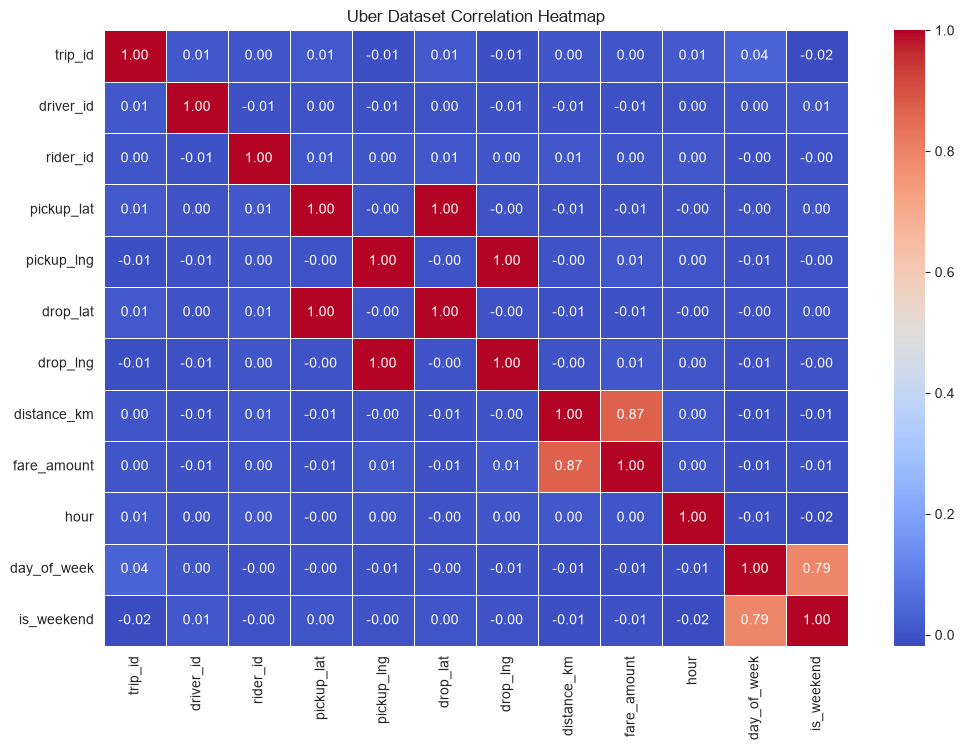

In [48]:

# ============================================================
# 12. CORRELATION HEATMAP
# ============================================================

plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(
    include="number"
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Uber Dataset Correlation Heatmap")
plt.show()



In [49]:

# ============================================================
# 13. FEATURE SELECTION
# ============================================================

features = [
    "distance_km",
    "city",
    "hour",
    "day_of_week",
    "is_weekend",
    "payment_method"
]

target = "fare_amount"

X = df[features]
y = df[target]



In [50]:

# ============================================================
# 14. TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)


# ============================================================
# 15. PREPROCESSING
# ============================================================

numeric_features = [
    "distance_km",
    "hour",
    "day_of_week",
    "is_weekend"
]

categorical_features = [
    "city",
    "payment_method"
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])




Training Shape: (34030, 6)
Testing Shape: (8508, 6)


In [53]:

# ============================================================
# 16. MODEL TRAINING
# ============================================================

models = {

    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

trained_models = {}
results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

    print(name, "Training Completed!")



Linear Regression Training Completed!
Random Forest Training Completed!
Gradient Boosting Training Completed!


In [54]:

# ============================================================
# 17. XGBOOST MODEL
# ============================================================

from xgboost import XGBRegressor
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_pipeline.fit(X_train, y_train)

xgb_predictions = xgb_pipeline.predict(X_test)

trained_models["XGBoost"] = xgb_pipeline

print("XGBoost Training Completed!")



XGBoost Training Completed!


In [55]:

# ============================================================
# 18. FINAL MODEL COMPARISON
# ============================================================

xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_mse = mean_squared_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(xgb_mse)
xgb_r2 = r2_score(y_test, xgb_predictions)

results.append({
    "Model": "XGBoost",
    "MAE": xgb_mae,
    "MSE": xgb_mse,
    "RMSE": xgb_rmse,
    "R2 Score": xgb_r2
})

results_df = pd.DataFrame(results)

results_df = results_df.sort_values("RMSE")

print("\n--- FINAL MODEL COMPARISON ---")
print(results_df.to_string(index=False))



--- FINAL MODEL COMPARISON ---
            Model      MAE       MSE     RMSE  R2 Score
Linear Regression 2.473556  9.566764 3.093019  0.754249
Gradient Boosting 2.477112  9.598704 3.098177  0.753428
          XGBoost 2.485278  9.745842 3.121833  0.749649
    Random Forest 2.597419 10.875025 3.297730  0.720642


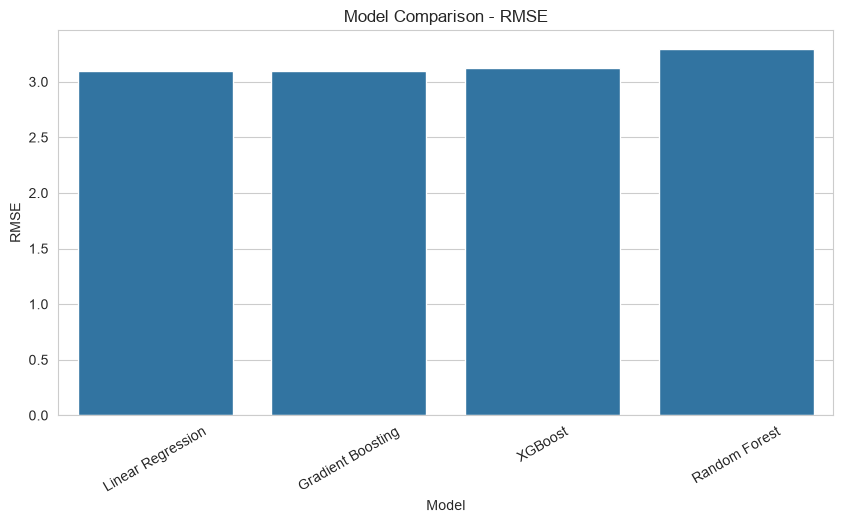

In [56]:


# ============================================================
# 19. MODEL COMPARISON GRAPH
# ============================================================

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("Model Comparison - RMSE")
plt.xticks(rotation=30)
plt.show()



In [57]:

# ============================================================
# 20. BEST MODEL SELECTION
# ============================================================

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

print("\nBEST MODEL:", best_model_name)

print("MAE:", mean_absolute_error(
    y_test, best_predictions
))

print("RMSE:", np.sqrt(
    mean_squared_error(y_test, best_predictions
)))

print("R2 SCORE:", r2_score(
    y_test, best_predictions
))




BEST MODEL: Linear Regression
MAE: 2.4735563646346224
RMSE: 3.0930185167959845
R2 SCORE: 0.7542487756678886


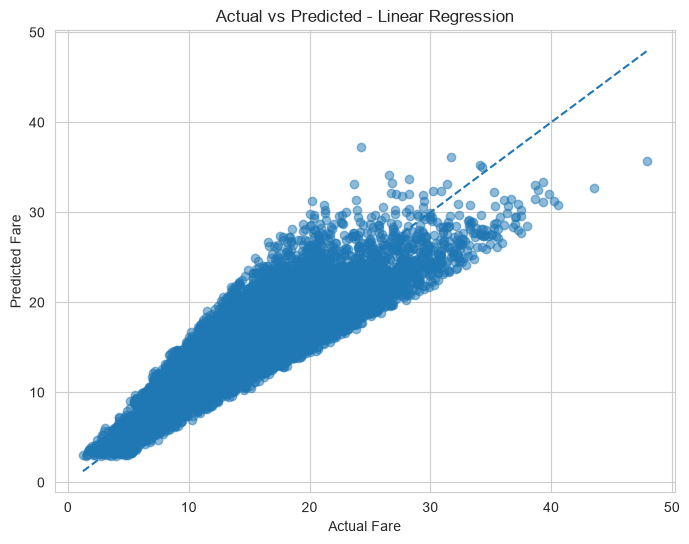

In [58]:

# ============================================================
# 21. ACTUAL VS PREDICTED GRAPH
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.5
)

min_value = min(
    y_test.min(),
    best_predictions.min()
)

max_value = max(
    y_test.max(),
    best_predictions.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")

plt.title(
    f"Actual vs Predicted - {best_model_name}"
)

plt.show()



In [59]:

# ============================================================
# 22. FEATURE IMPORTANCE
# ============================================================

model_step = best_model.named_steps["model"]

if hasattr(model_step, "feature_importances_"):

    feature_names = (
        best_model
        .named_steps["preprocessor"]
        .get_feature_names_out()
    )

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": model_step.feature_importances_
    })

    importance_df = importance_df.sort_values(
        "Importance",
        ascending=False
    )

    print("\n--- FEATURE IMPORTANCE ---")
    print(importance_df.head(15).to_string(index=False))

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=importance_df.head(15),
        x="Importance",
        y="Feature"
    )

    plt.title("Top 15 Feature Importance")
    plt.show()

else:
    print("Feature Importance is not available for this model.")



Feature Importance is not available for this model.


In [61]:

# ============================================================
# 23. SAVE FINAL MODEL
# ============================================================
import os


os.makedirs("models", exist_ok=True)

joblib.dump(
    best_model,
    "models/fare_model.pkl"
)

print("\nFINAL MODEL SAVED SUCCESSFULLY!")
print("Selected Model:", best_model_name)


# ============================================================
# 24. LOAD MODEL AND TEST PREDICTION
# ============================================================

loaded_model = joblib.load(
    "models/fare_model.pkl"
)

sample_ride = pd.DataFrame([{
    "distance_km": 10,
    "city": X_train["city"].mode()[0],
    "hour": 18,
    "day_of_week": 2,
    "is_weekend": 0,
    "payment_method": X_train["payment_method"].mode()[0]
}])

predicted_fare = loaded_model.predict(sample_ride)

print("\n--- SAMPLE FARE PREDICTION ---")
print("Distance: 10 KM")
print("Predicted Fare: ₹", round(predicted_fare[0], 2))

print("\nUBER FARE PREDICTION PROJECT COMPLETED!")



FINAL MODEL SAVED SUCCESSFULLY!
Selected Model: Linear Regression

--- SAMPLE FARE PREDICTION ---
Distance: 10 KM
Predicted Fare: ₹ 21.53

UBER FARE PREDICTION PROJECT COMPLETED!
